In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_blobs

np.random.seed(20)

In [2]:
def euclidean_distance(x1, x2):
    return np.sqrt(np.sum((x1 - x2)**2))

In [ ]:
# K-Means++

In [3]:
class KMeansPlusPlus():
    
    def __init__(self, K, max_iters=100, plot_steps=False, random_state=272):
        self.K = K
        self.max_iters = max_iters
        self.plot_steps = plot_steps
        self.fig_number = 0
        self.random_state = random_state
        self.clusters = [[] for _ in range(self.K)]
        self.centroids = None

    def fit(self, X):

        self.X = X
        self.n_samples, self.n_features = X.shape

        self.centroids = self._initialize_centroids()

        previous_labels = None

        for _ in range(self.max_iters):

            self.clusters = self._create_clusters(
                self.centroids
            )
            current_labels = self._get_cluster_labels(
                self.clusters
            )

            if previous_labels is not None:

                if np.array_equal(
                    previous_labels,
                    current_labels
                ):
                    break

            self.centroids = self._get_centroids(
                self.clusters
            )

            previous_labels = current_labels

            if self.plot_steps:
                self.plot()

        return self._get_cluster_labels(
            self.clusters
        )

    def _initialize_centroids(self):

        rng = np.random.default_rng(
            seed=self.random_state
        )

        centroids = []

        first_idx = rng.integers(
            self.n_samples
        )

        centroids.append(
            self.X[first_idx]
        )
        for _ in range(1, self.K):

            distances = np.array([

                min(
                    np.sum(
                        (sample - centroid) ** 2
                    )

                    for centroid in centroids
                )

                for sample in self.X
            ])

            probabilities = (
                distances /
                np.sum(distances)
            )

            next_idx = rng.choice(
                self.n_samples,
                p=probabilities
            )

            centroids.append(
                self.X[next_idx]
            )

        return np.array(centroids)

    def _get_cluster_labels(self, clusters):

        labels = np.empty(
            self.n_samples
        )

        for cluster_idx, cluster in enumerate(
            clusters
        ):

            for sample_index in cluster:

                labels[sample_index] = cluster_idx

        return labels

    def _create_clusters(self, centroids):

        clusters = [
            [] for _ in range(self.K)
        ]

        for idx, sample in enumerate(self.X):

            centroid_idx = self._closest_centroid(
                sample,
                centroids
            )

            clusters[centroid_idx].append(
                idx
            )

        return clusters

    def _closest_centroid(
        self,
        sample,
        centroids
    ):

        distances = [
            euclidean_distance(
                sample,
                point
            )

            for point in centroids
        ]

        closest_index = np.argmin(
            distances
        )

        return closest_index

    def _get_centroids(self, clusters):

        centroids = np.zeros(
            (self.K, self.n_features)
        )

        for cluster_idx, cluster in enumerate(
            clusters
        ):

            cluster_mean = np.mean(
                self.X[cluster],
                axis=0
            )

            centroids[cluster_idx] = (
                cluster_mean
            )

        return centroids

    def plot(self):

        self.fig_number += 1

        _, ax = plt.subplots(
            figsize=(6, 4)
        )

        for index in self.clusters:

            point = self.X[index].T

            ax.scatter(*point)

        for point in self.centroids:

            ax.scatter(
                *point,
                marker="x",
                color='black',
                linewidth=2
            )

        plt.xlabel(
            'Iteration: ' +
            str(self.fig_number)
        )

        plt.grid(True)
        plt.show()

In [4]:
X, y = make_blobs(
    centers=4,
    n_samples=50,
    n_features=2,
    shuffle=True,
    random_state=272
)

n_clusters = len(np.unique(y))

print(f'X.shape: {X.shape}')
print(f'y.shape: {y.shape}')
print(f'n_clusters: {n_clusters}')

X.shape: (50, 2)
y.shape: (50,)
n_clusters: 4


In [5]:
X[0:10]

array([[-1.7214614 , -5.70633574],
       [-5.81623847,  8.36037108],
       [-0.79582536, -5.8347217 ],
       [-4.9868333 ,  6.56176804],
       [-5.32085737, 10.05336814],
       [-0.51149662, -4.94563944],
       [10.99348975, -2.79948944],
       [-6.2803617 , -4.66686882],
       [-5.01498597, -6.38332099],
       [-5.20164013,  5.91755293]])

In [6]:
y[0:10]

array([2, 0, 2, 0, 0, 2, 1, 3, 3, 0])

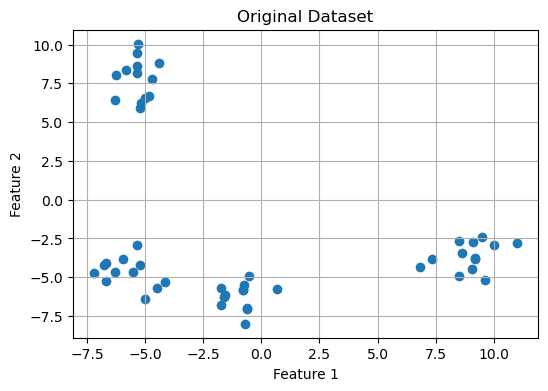

In [7]:
plt.figure(figsize=(6, 4))

plt.scatter(
    X[:, 0],
    X[:, 1]
)

plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Original Dataset')

plt.grid(True)
plt.show()

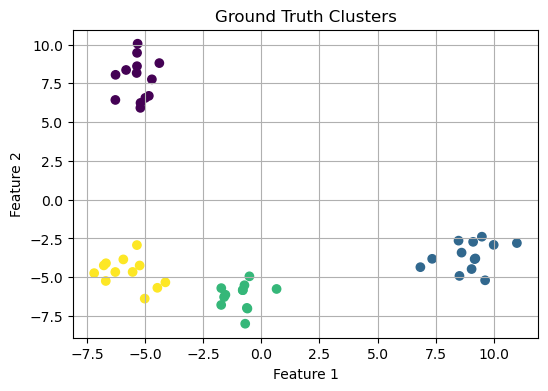

In [8]:
plt.figure(figsize=(6, 4))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y
)

plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Ground Truth Clusters')

plt.grid(True)
plt.show()

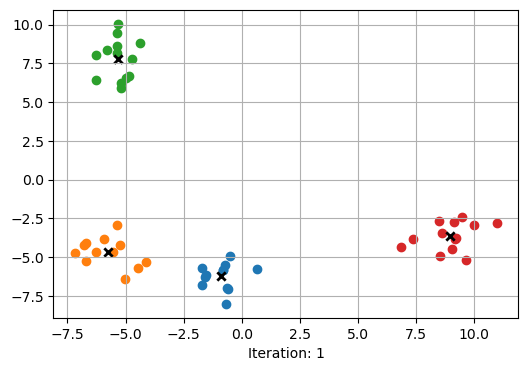

In [9]:
k = KMeansPlusPlus(
    K=n_clusters,
    max_iters=150,
    plot_steps=True,
    random_state=3
)

y_pred = k.fit(X)

In [10]:
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics import normalized_mutual_info_score

ari = adjusted_rand_score(y, y_pred)

nmi = normalized_mutual_info_score(
    y,
    y_pred
)

print(f"ARI: {ari:.2f}")
print(f"NMI: {nmi:.2f}")

ARI: 1.00
NMI: 1.00


In [11]:
X = np.array([
    # Face outline
    [-5,0],[-4.9,1],[-4.7,2],[-4.3,3],[-3.7,3.9],
    [-3,4.5],[-2,4.8],[-1,5],[0,5],
    [1,5],[2,4.8],[3,4.5],[3.7,3.9],
    [4.3,3],[4.7,2],[4.9,1],[5,0],

    [4.9,-1],[4.7,-2],[4.3,-3],[3.7,-3.9],
    [3,-4.5],[2,-4.8],[1,-5],[0,-5],
    [-1,-5],[-2,-4.8],[-3,-4.5],[-3.7,-3.9],
    [-4.3,-3],[-4.7,-2],[-4.9,-1],

    # Left eye - dense cluster
    [-2.7,2.5],[-2.6,2.7],[-2.5,2.9],[-2.3,3.0],
    [-2.1,2.9],[-2.0,2.7],
    [-2.0,2.5],[-2.1,2.3],[-2.3,2.2],
    [-2.5,2.3],[-2.7,2.5],

    # Right eye - dense cluster
    [2.0,2.5],[2.0,2.7],[2.1,2.9],[2.3,3.0],
    [2.5,2.9],[2.6,2.7],
    [2.7,2.5],[2.5,2.3],[2.3,2.2],
    [2.1,2.3],[2.0,2.5],

    # Smile - dense curved cluster
    [-3,-1],[-2.8,-1.4],[-2.5,-1.8],[-2.2,-2.1],
    [-1.8,-2.4],[-1.4,-2.7],
    [-1,-2.9],[-0.5,-3.1],[0,-3.2],
    [0.5,-3.1],[1,-2.9],[1.4,-2.7],
    [1.8,-2.4],[2.2,-2.1],[2.5,-1.8],
    [2.8,-1.4],[3,-1]
])

y = np.array(
    [0]*32 +
    [1]*11 +
    [2]*11 +
    [3]*17
)

n_clusters = len(np.unique(y))

print(f'X.shape: {X.shape}')
print(f'y.shape: {y.shape}')
print(f'n_clusters: {n_clusters}')

X.shape: (71, 2)
y.shape: (71,)
n_clusters: 4


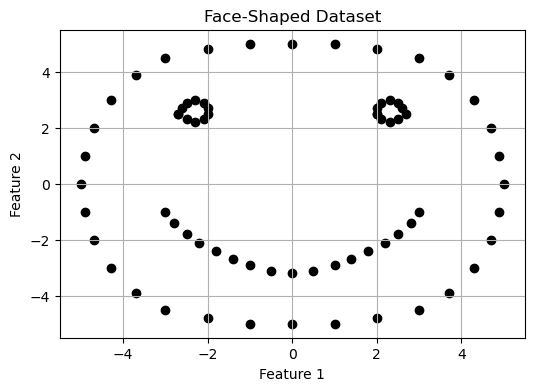

In [12]:
plt.figure(figsize=(6, 4))

plt.scatter(
    X[:, 0],
    X[:, 1],
    color='black'
)

plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Face-Shaped Dataset')
plt.grid(True)
plt.show()

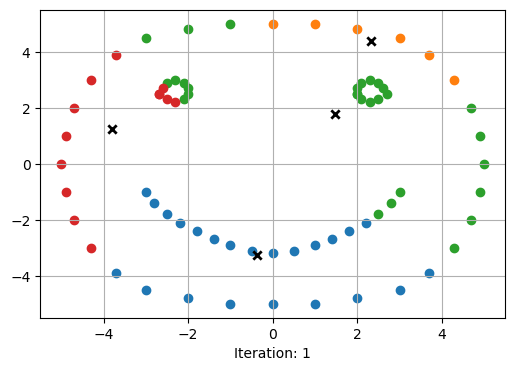

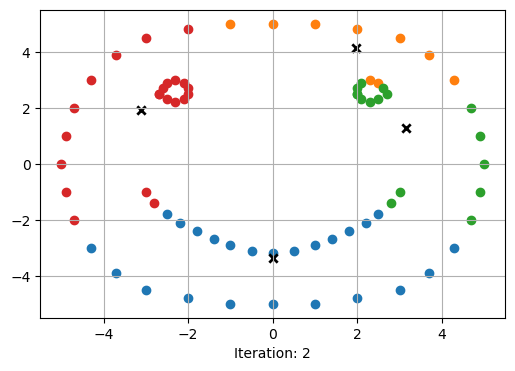

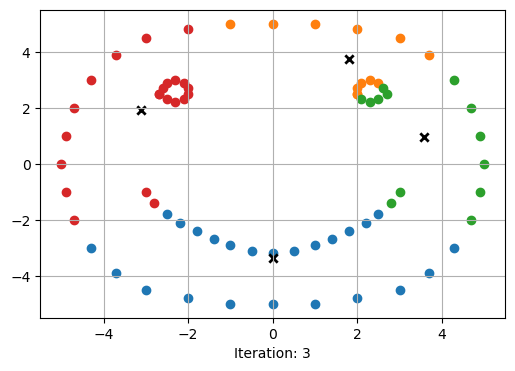

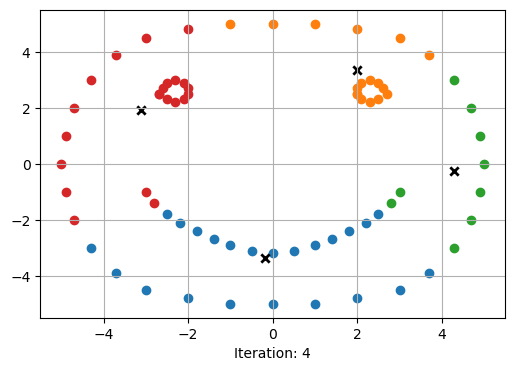

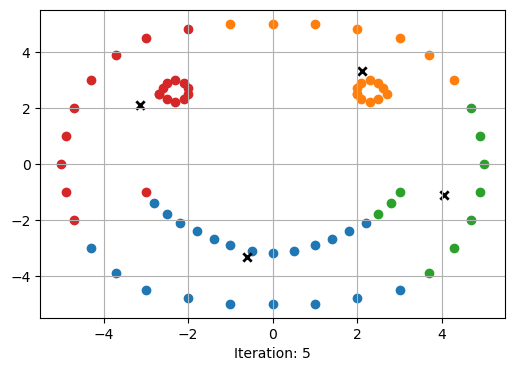

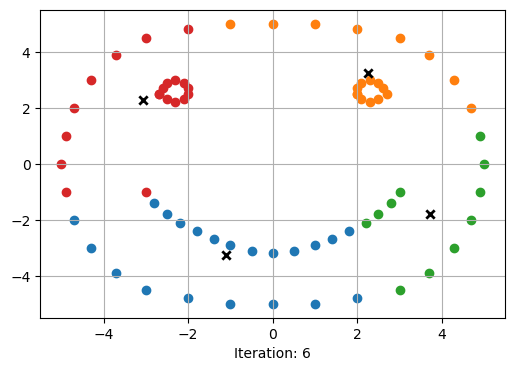

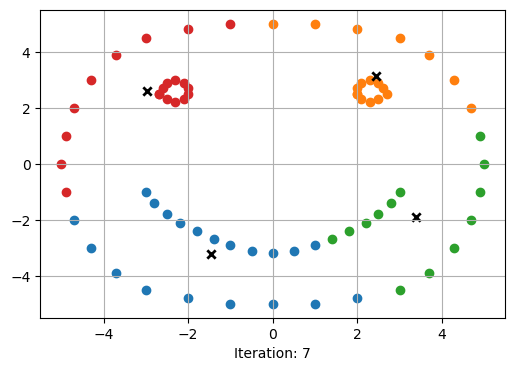

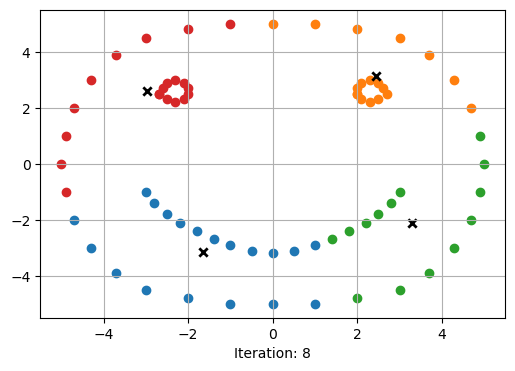

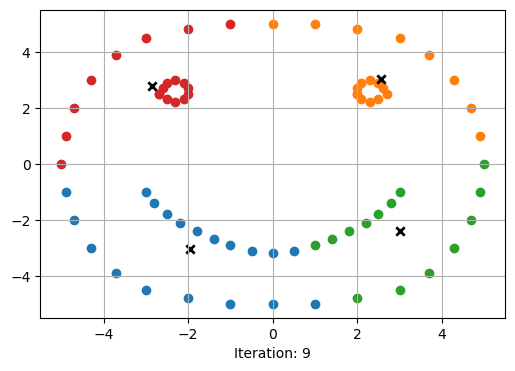

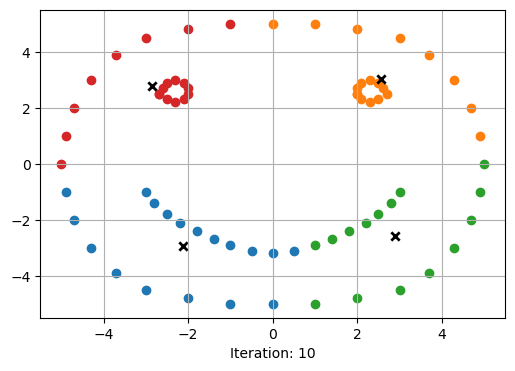

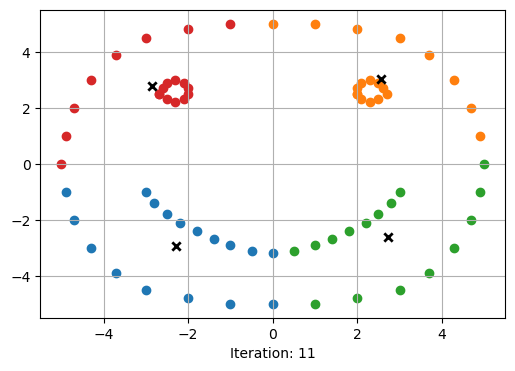

In [13]:
k = KMeansPlusPlus(
    K=n_clusters,
    max_iters=150,
    plot_steps=True,
    random_state=3
)

face_labels = k.fit(
    X
)

In [14]:
ari_face = adjusted_rand_score(
    y,
    face_labels
)

nmi_face = normalized_mutual_info_score(
    y,
    face_labels
)

print("ARI:", ari_face)
print("NMI:", nmi_face)

ARI: 0.21862640575024933
NMI: 0.44556407817972155


In [15]:
from sklearn.datasets import load_iris

iris = load_iris()

X_iris = iris.data
y_iris = iris.target

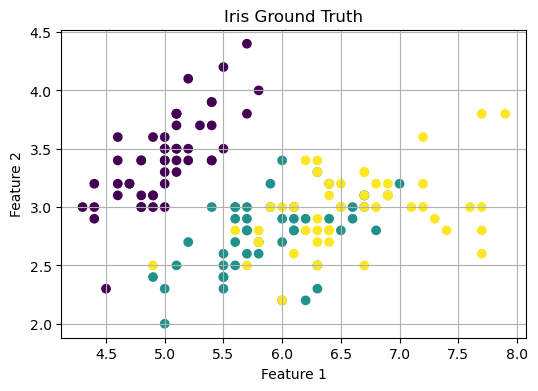

In [16]:
plt.figure(figsize=(6, 4))

plt.scatter(
    X_iris[:, 0],
    X_iris[:, 1],
    c=y_iris
)

plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Iris Ground Truth')

plt.grid(True)
plt.show()

In [17]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_iris_pca = pca.fit_transform(
    X_iris
)

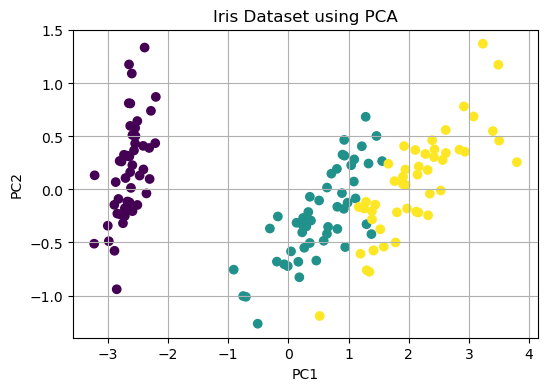

In [18]:
plt.figure(figsize=(6, 4))

plt.scatter(
    X_iris_pca[:, 0],
    X_iris_pca[:, 1],
    c=y_iris
)

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Iris Dataset using PCA')

plt.grid(True)
plt.show()

In [19]:
kmeans_pp_iris = KMeansPlusPlus(
    K=3,
    max_iters=150,
    plot_steps=False,
    random_state=3
)

iris_labels = kmeans_pp_iris.fit(
    X_iris
)

In [20]:
ari_iris = adjusted_rand_score(
    y_iris,
    iris_labels
)

nmi_iris = normalized_mutual_info_score(
    y_iris,
    iris_labels
)

print("ARI:", ari_iris)
print("NMI:", nmi_iris)

ARI: 0.7163421126838476
NMI: 0.7419116631817836


In [36]:
# K-Means with Immediate Update

In [21]:
class KMeansImmediate():
    
    def __init__(self, K, max_iters=100, plot_steps=False, random_state=272):
        self.K = K
        self.max_iters = max_iters
        self.plot_steps = plot_steps
        self.fig_number = 0
        self.random_state = random_state
        self.clusters = [[] for _ in range(self.K)]
        self.centroids = None

    def fit(self, X):
        self.X = X
        self.n_samples, self.n_features = X.shape

        rng = np.random.default_rng(seed=self.random_state)

        random_sample_idxs = rng.choice(
            self.n_samples,
            self.K,
            replace=False
        )

        self.centroids = np.array([
            self.X[idx]
            for idx in random_sample_idxs
        ])

        previous_labels = None

        for _ in range(self.max_iters):

            self.clusters = self._create_clusters_immediate()

            current_labels = self._get_cluster_labels(
                self.clusters
            )

            if previous_labels is not None:
                if np.array_equal(previous_labels, current_labels):
                    break

            previous_labels = current_labels

            if self.plot_steps:
                self.plot()

        return self._get_cluster_labels(self.clusters)

    def _get_cluster_labels(self, clusters):

        labels = np.empty(self.n_samples)

        for cluster_idx, cluster in enumerate(clusters):

            for sample_index in cluster:
                labels[sample_index] = cluster_idx

        return labels

    def _create_clusters_immediate(self):

        clusters = [[] for _ in range(self.K)]

        centroids = self.centroids.copy()

        for idx, sample in enumerate(self.X):

            centroid_idx = self._closest_centroid(
                sample,
                centroids
            )
            clusters[centroid_idx].append(idx)

            centroids[centroid_idx] = np.mean(
                self.X[clusters[centroid_idx]],
                axis=0
            )

        self.centroids = centroids

        return clusters

    def _closest_centroid(self, sample, centroids):

        distances = [
            euclidean_distance(sample, point)
            for point in centroids
        ]

        closest_index = np.argmin(distances)

        return closest_index

    def plot(self):

        self.fig_number += 1

        _, ax = plt.subplots(figsize=(6, 4))

        for index in self.clusters:

            point = self.X[index].T

            ax.scatter(*point)

        for point in self.centroids:

            ax.scatter(
                *point,
                marker="x",
                color='black',
                linewidth=2
            )

        plt.xlabel(
            'Iteration: ' + str(self.fig_number)
        )

        plt.grid(True)
        plt.show()

In [22]:
n_clusters = 4

X, y = make_blobs(
    centers=n_clusters,
    n_samples=50,
    n_features=2,
    shuffle=True,
    random_state=272
)

In [23]:
X[0:10]

array([[-1.7214614 , -5.70633574],
       [-5.81623847,  8.36037108],
       [-0.79582536, -5.8347217 ],
       [-4.9868333 ,  6.56176804],
       [-5.32085737, 10.05336814],
       [-0.51149662, -4.94563944],
       [10.99348975, -2.79948944],
       [-6.2803617 , -4.66686882],
       [-5.01498597, -6.38332099],
       [-5.20164013,  5.91755293]])

In [24]:
y[0:10]

array([2, 0, 2, 0, 0, 2, 1, 3, 3, 0])

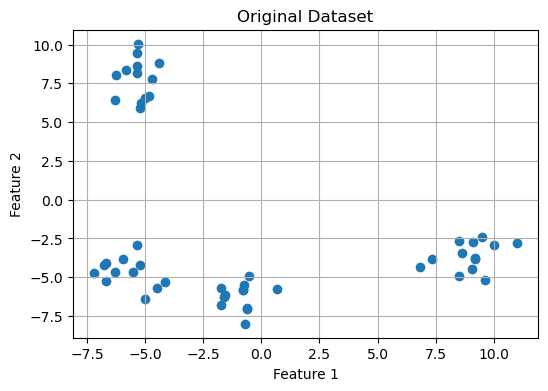

In [25]:
plt.figure(figsize=(6, 4))

plt.scatter(
    X[:, 0],
    X[:, 1]
)

plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Original Dataset')

plt.grid(True)
plt.show()

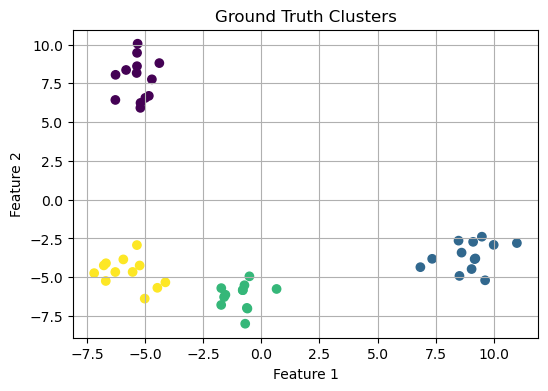

In [26]:
plt.figure(figsize=(6, 4))

plt.scatter(
    X[:, 0],
    X[:, 1],
    c=y
)

plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Ground Truth Clusters')

plt.grid(True)
plt.show()

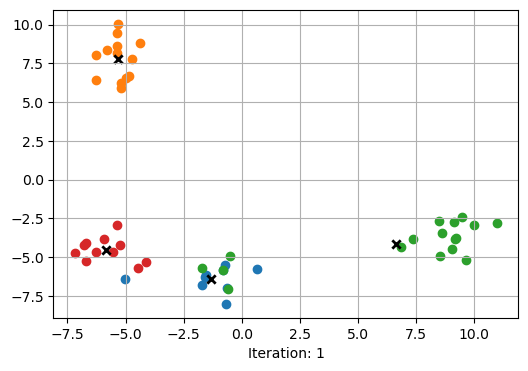

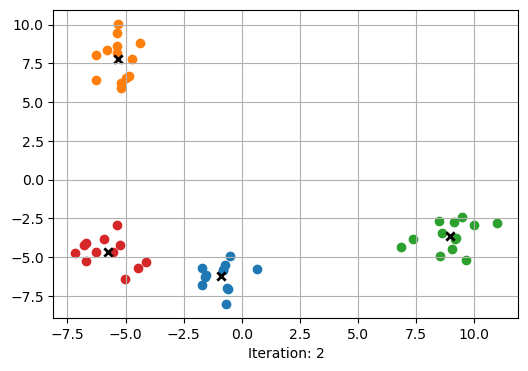

In [27]:
k = KMeansImmediate(
    K=n_clusters,
    max_iters=150,
    plot_steps=True,
    random_state=3
)

predicted_labels = k.fit(X)

In [93]:
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics import normalized_mutual_info_score

ari = adjusted_rand_score(
    y,
    predicted_labels
)

nmi = normalized_mutual_info_score(
    y,
    predicted_labels
)

print("ARI:", ari)
print("NMI:", nmi)

ARI: 1.0
NMI: 1.0


In [94]:
X = np.array([
    # Face outline
    [-5,0],[-4.9,1],[-4.7,2],[-4.3,3],[-3.7,3.9],
    [-3,4.5],[-2,4.8],[-1,5],[0,5],
    [1,5],[2,4.8],[3,4.5],[3.7,3.9],
    [4.3,3],[4.7,2],[4.9,1],[5,0],

    [4.9,-1],[4.7,-2],[4.3,-3],[3.7,-3.9],
    [3,-4.5],[2,-4.8],[1,-5],[0,-5],
    [-1,-5],[-2,-4.8],[-3,-4.5],[-3.7,-3.9],
    [-4.3,-3],[-4.7,-2],[-4.9,-1],

    # Left eye - dense cluster
    [-2.7,2.5],[-2.6,2.7],[-2.5,2.9],[-2.3,3.0],
    [-2.1,2.9],[-2.0,2.7],
    [-2.0,2.5],[-2.1,2.3],[-2.3,2.2],
    [-2.5,2.3],[-2.7,2.5],

    # Right eye - dense cluster
    [2.0,2.5],[2.0,2.7],[2.1,2.9],[2.3,3.0],
    [2.5,2.9],[2.6,2.7],
    [2.7,2.5],[2.5,2.3],[2.3,2.2],
    [2.1,2.3],[2.0,2.5],

    # Smile - dense curved cluster
    [-3,-1],[-2.8,-1.4],[-2.5,-1.8],[-2.2,-2.1],
    [-1.8,-2.4],[-1.4,-2.7],
    [-1,-2.9],[-0.5,-3.1],[0,-3.2],
    [0.5,-3.1],[1,-2.9],[1.4,-2.7],
    [1.8,-2.4],[2.2,-2.1],[2.5,-1.8],
    [2.8,-1.4],[3,-1]
])

y = np.array(
    [0]*32 +
    [1]*11 +
    [2]*11 +
    [3]*17
)

n_clusters = len(np.unique(y))

print(f'X.shape: {X.shape}')
print(f'y.shape: {y.shape}')
print(f'n_clusters: {n_clusters}')

X.shape: (71, 2)
y.shape: (71,)
n_clusters: 4


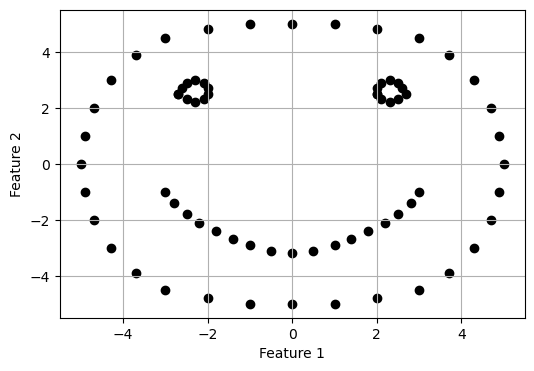

In [95]:
plt.figure(figsize=(6, 4))

plt.scatter(
    X[:, 0],
    X[:, 1],
    color='black'
)

plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.grid(True)
plt.show()

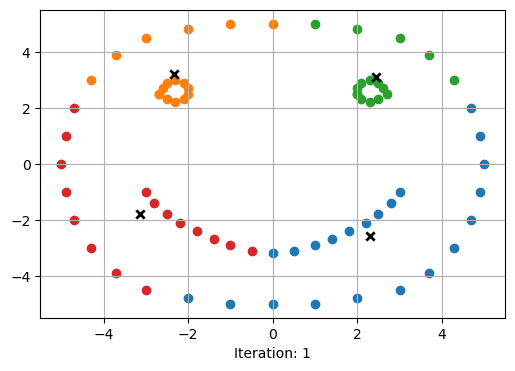

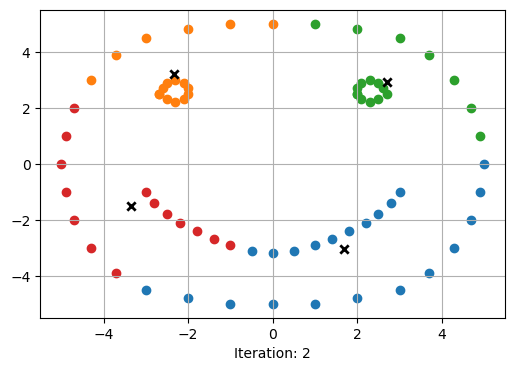

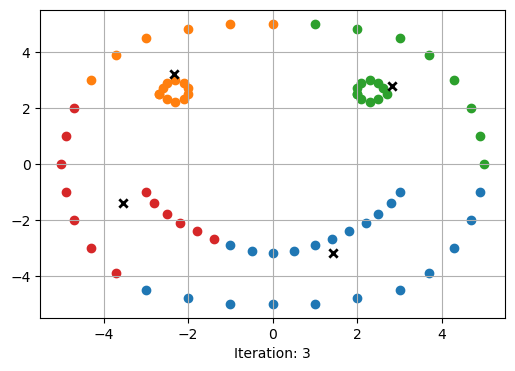

In [96]:
k = KMeansImmediate(
    K=4,
    max_iters=150,
    plot_steps=True,
    random_state=3
)

face_labels = k.fit(X)

In [97]:
ari_face = adjusted_rand_score(
    y,
    face_labels
)

nmi_face = normalized_mutual_info_score(
    y,
    face_labels
)

print("ARI:", ari_face)
print("NMI:", nmi_face)

ARI: 0.23242806502455207
NMI: 0.45353701664465684


In [98]:
from sklearn.datasets import load_iris

iris = load_iris()

X_iris = iris.data
y_iris = iris.target

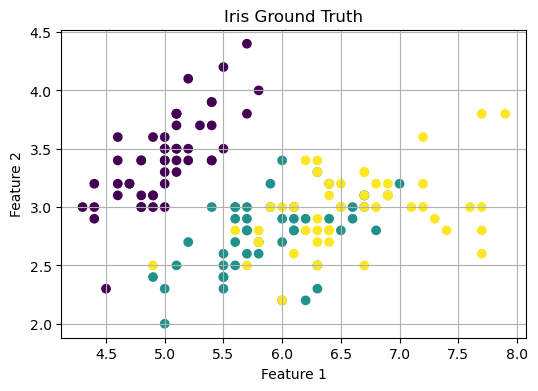

In [99]:
plt.figure(figsize=(6, 4))

plt.scatter(
    X_iris[:, 0],
    X_iris[:, 1],
    c=y_iris
)

plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Iris Ground Truth')

plt.grid(True)
plt.show()

In [100]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_iris_pca = pca.fit_transform(X_iris)

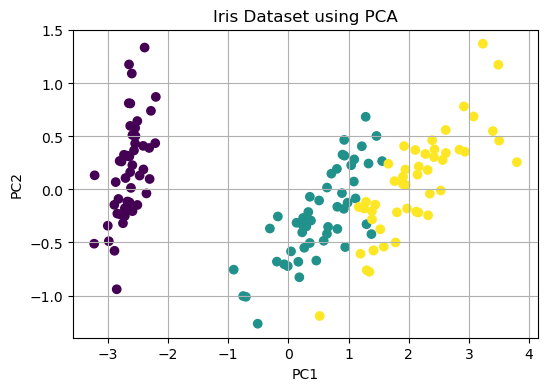

In [101]:
plt.figure(figsize=(6, 4))

plt.scatter(
    X_iris_pca[:, 0],
    X_iris_pca[:, 1],
    c=y_iris
)

plt.xlabel('PC1')
plt.ylabel('PC2')
plt.title('Iris Dataset using PCA')

plt.grid(True)
plt.show()

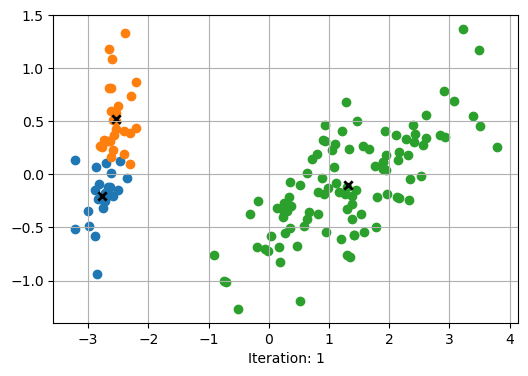

In [102]:
k = KMeansImmediate(
    K=3,
    max_iters=150,
    plot_steps=True,
    random_state=3
)

iris_labels = k.fit(X_iris_pca)

In [103]:
ari_iris = adjusted_rand_score(
    y_iris,
    iris_labels
)

nmi_iris = normalized_mutual_info_score(
    y_iris,
    iris_labels
)

print("ARI:", ari_iris)
print("NMI:", nmi_iris)

ARI: 0.4402831388889892
NMI: 0.647816061304139
